In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
df = pd.read_csv("bank+marketing/bank-full.csv", sep=";")

# Dastlabki 5 ta qator
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
# Qator va ustunlar soni
print("Dataset o'lchami:", df.shape)

# Ustunlar nomlari
print("\nUstunlar:")
print(df.columns.tolist())

# Ma'lumot turlari
print("\nMa'lumot turlari:")
print(df.dtypes)

# Bo'sh qiymatlarni tekshirish
print("\nBo'sh qiymatlar:")
print(df.isnull().sum())

Dataset o'lchami: (45211, 17)

Ustunlar:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Ma'lumot turlari:
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y            object
dtype: object

Bo'sh qiymatlar:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64


In [4]:
# 1. Model ishlab chiqish

# 1.1. Mustaqil va bog‘liq o‘zgaruvchilarni ajratish

X = df[['age', 'day', 'duration',
        'campaign', 'pdays', 'previous']]

y = df['balance']

print("Mustaqil o'zgaruvchilar:")
print(X.head())

print("\nBog'liq o'zgaruvchi:")
print(y.head())

Mustaqil o'zgaruvchilar:
   age  day  duration  campaign  pdays  previous
0   58    5       261         1     -1         0
1   44    5       151         1     -1         0
2   33    5        76         1     -1         0
3   47    5        92         1     -1         0
4   33    5       198         1     -1         0

Bog'liq o'zgaruvchi:
0    2143
1      29
2       2
3    1506
4       1
Name: balance, dtype: int64


In [5]:
# 1.2. Train va Test qismlariga ajratish

# Ma’lumotlarning 80 foizi modelni o‘qitish, 20 foizi esa modelni sinash uchun ishlatiladi.

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (36168, 6)
Test: (9043, 6)


In [6]:
# 2. Oddiy chiziqli regressiya va ko‘p chiziqli regressiya

# 2.1. Oddiy chiziqli regressiya
# Bunda bitta mustaqil o‘zgaruvchi ishlatiladi. Biz mijozning yoshiga qarab uning hisobidagi mablag‘ni bashorat qilamiz.

# Mustaqil o'zgaruvchi
X_simple = df[['age']]

# Train va test
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_simple, y,
    test_size=0.2,
    random_state=42
)

# Model yaratish
model_simple = LinearRegression()

# Modelni o'qitish
model_simple.fit(X_train_s, y_train_s)

# Bashorat
y_pred_simple = model_simple.predict(X_test_s)

# Natijalar
print("Intercept:", model_simple.intercept_)
print("Coefficient:", model_simple.coef_[0])

Intercept: 208.30781997977192
Coefficient: 28.16308703741565


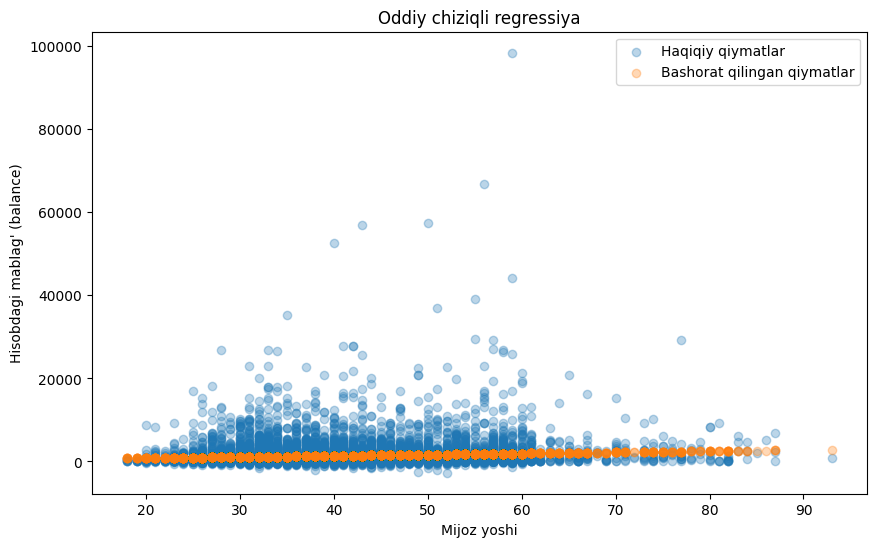

In [7]:
plt.figure(figsize=(10, 6))

plt.scatter(X_test_s['age'], y_test_s,
            alpha=0.3, label="Haqiqiy qiymatlar")

plt.scatter(X_test_s['age'], y_pred_simple,
            alpha=0.3, label="Bashorat qilingan qiymatlar")

plt.xlabel("Mijoz yoshi")
plt.ylabel("Hisobdagi mablag' (balance)")
plt.title("Oddiy chiziqli regressiya")
plt.legend()
plt.show()

In [8]:
# 2.2. Ko‘p chiziqli regressiya
# Bunda bir nechta mustaqil o‘zgaruvchilar ishlatiladi.

# Model yaratish
model_multi = LinearRegression()

# Modelni o'qitish
model_multi.fit(X_train, y_train)

# Bashorat
y_pred_multi = model_multi.predict(X_test)

# Koeffitsiyentlarni chiqarish
print("Intercept:", model_multi.intercept_)

for feature, coef in zip(X.columns, model_multi.coef_):
    print(feature, ":", coef)

Intercept: 140.53299830162337
age : 28.206425445602857
day : 1.8783818605565201
duration : 0.29314464262684514
campaign : -16.81074798205458
pdays : -0.1154665150244758
previous : 20.878408323644397


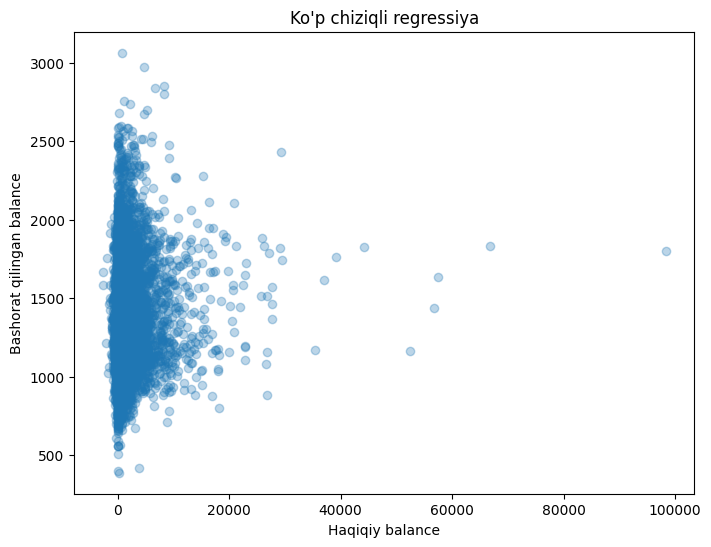

In [9]:
# Haqiqiy va bashorat qilingan qiymatlarni taqqoslaymiz:

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_multi, alpha=0.3)

plt.xlabel("Haqiqiy balance")
plt.ylabel("Bashorat qilingan balance")
plt.title("Ko'p chiziqli regressiya")

plt.show()

In [10]:
# 3. Polinomial regressiya

# Polinomial regressiya o‘zgaruvchilar orasidagi chiziqli bo‘lmagan munosabatlarni ifodalash uchun ishlatiladi.
# Biz mijoz yoshi va hisobidagi mablag‘ o‘rtasidagi munosabatni o‘rganamiz.

# Polinomial xususiyatlar yaratish
poly = PolynomialFeatures(degree=2)

X_poly_train = poly.fit_transform(X_train_s)
X_poly_test = poly.transform(X_test_s)

# Model yaratish
model_poly = LinearRegression()

# O'qitish
model_poly.fit(X_poly_train, y_train_s)

# Bashorat
y_pred_poly = model_poly.predict(X_poly_test)

print("Polinomial regressiya bajarildi.")

Polinomial regressiya bajarildi.


In [11]:
# 3.1. Haqiqiy qiymatlar va bashoratlarni chiqarish

print("Haqiqiy qiymatlar:")
print(y_test_s.head(10).values)

print("\nBashorat qilingan qiymatlar:")
print(y_pred_poly[:10])

Haqiqiy qiymatlar:
[ 580 3644  538 1773  217 1134 1085  127    3  258]

Bashorat qilingan qiymatlar:
[1269.86344081 1457.88091933 1070.89341628 1317.40318789 1788.60294533
 1088.44110421 1067.51599997 1207.82311893 1106.31909532 1227.26731972]


In [12]:
# 3.2. Model koeffitsiyentlarini chiqarish

print("Intercept:", model_poly.intercept_)

print("Koeffitsiyentlar:")
print(model_poly.coef_)

Intercept: 1357.2299580963197
Koeffitsiyentlar:
[  0.         -26.90229291   0.61795325]


In [13]:
# 3.3. Modelni baholash

from sklearn.metrics import mean_squared_error, r2_score

mse_poly = mean_squared_error(y_test_s, y_pred_poly)
r2_poly = r2_score(y_test_s, y_pred_poly)

print("MSE:", mse_poly)
print("R-squared:", r2_poly)

MSE: 9707494.097204186
R-squared: 0.009112199328394577


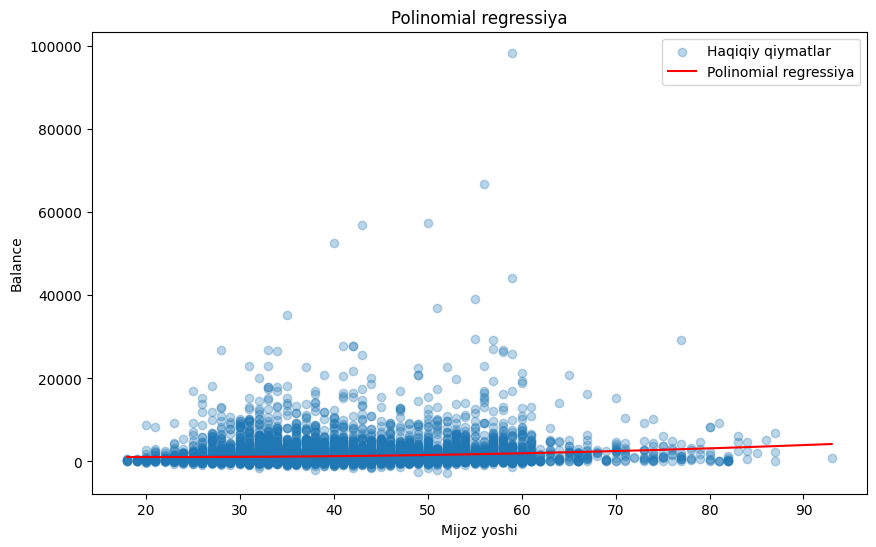

In [14]:
plt.figure(figsize=(10, 6))

plt.scatter(X_test_s['age'], y_test_s,
            alpha=0.3, label="Haqiqiy qiymatlar")

sorted_indices = np.argsort(X_test_s['age'].values)

plt.plot(
    X_test_s['age'].values[sorted_indices],
    y_pred_poly[sorted_indices],
    color='red',
    label="Polinomial regressiya"
)

plt.xlabel("Mijoz yoshi")
plt.ylabel("Balance")
plt.title("Polinomial regressiya")
plt.legend()
plt.show()

In [15]:
# 4. Ko‘p o‘zgaruvchan polinomli chiziqli regressiya

# Bu usul bir nechta mustaqil o‘zgaruvchini polinomial xususiyatlarga aylantiradi.
# Masalan, age, day, duration, campaign, pdays, previous ustunlaridan foydalanamiz.
# Bu jarayonda boshlang‘ich 6 ta o‘zgaruvchidan ikkinchi darajali polinomial xususiyatlar hosil qilinadi.

# Polinomial xususiyatlarni yaratish
poly_multi = PolynomialFeatures(
    degree=2,
    include_bias=False
)

X_poly_multi_train = poly_multi.fit_transform(X_train)
X_poly_multi_test = poly_multi.transform(X_test)

# Model yaratish
model_poly_multi = LinearRegression()

# O'qitish
model_poly_multi.fit(X_poly_multi_train, y_train)

# Bashorat
y_pred_poly_multi = model_poly_multi.predict(
    X_poly_multi_test
)

print("Polinomial xususiyatlar soni:",
      X_poly_multi_train.shape[1])

Polinomial xususiyatlar soni: 27


In [16]:
# 4.1. Haqiqiy va bashorat qilingan qiymatlarni chiqarish

# Haqiqiy qiymatlar
print("Haqiqiy qiymatlar:")
print(y_test.head(10).values)

# Bashorat qilingan qiymatlar
print("\nBashorat qilingan qiymatlar:")
print(y_pred_poly_multi[:10])

# Model ko'rsatkichlari
print("\nModel parametrlari:")
print("Intercept:", model_poly_multi.intercept_)
print("Koeffitsiyentlar:", model_poly_multi.coef_)

# Polinomial xususiyatlar soni
print("\nPolinomial xususiyatlar soni:",
      X_poly_multi_train.shape[1])

Haqiqiy qiymatlar:
[ 580 3644  538 1773  217 1134 1085  127    3  258]

Bashorat qilingan qiymatlar:
[1359.38197512 1449.08049596 1172.69885699 1254.18327889 1725.9798731
 1028.9951717   904.79364783 1152.51507081 1123.28907143 1380.45740194]

Model parametrlari:
Intercept: 727.3733469826182
Koeffitsiyentlar: [-1.27636078e+01  5.34511644e+01  1.09074330e-01 -1.21574429e+01
 -8.22950173e-01 -6.06665346e-01  5.08551252e-01 -4.50602863e-01
  4.22237821e-03  5.97320448e-02  5.02514095e-03  1.41627478e+00
 -1.05230960e+00  2.12349318e-03 -8.97816848e-01  8.54401674e-02
  9.04503514e-02 -4.04307644e-05 -1.49377454e-02  9.42383075e-04
  2.32561249e-02  9.23593835e-01 -3.26498325e-02 -3.37539072e+00
 -2.60295662e-03 -1.16718875e-01 -1.02126114e-01]

Polinomial xususiyatlar soni: 27


In [17]:
# 4.2. Model sifatini baholash (MSE va R-squared)

mse_poly_multi = mean_squared_error(
    y_test, y_pred_poly_multi
)

r2_poly_multi = r2_score(
    y_test, y_pred_poly_multi
)

print("MSE:", mse_poly_multi)
print("R-squared:", r2_poly_multi)

MSE: 9697285.176998373
R-squared: 0.01015426995843327


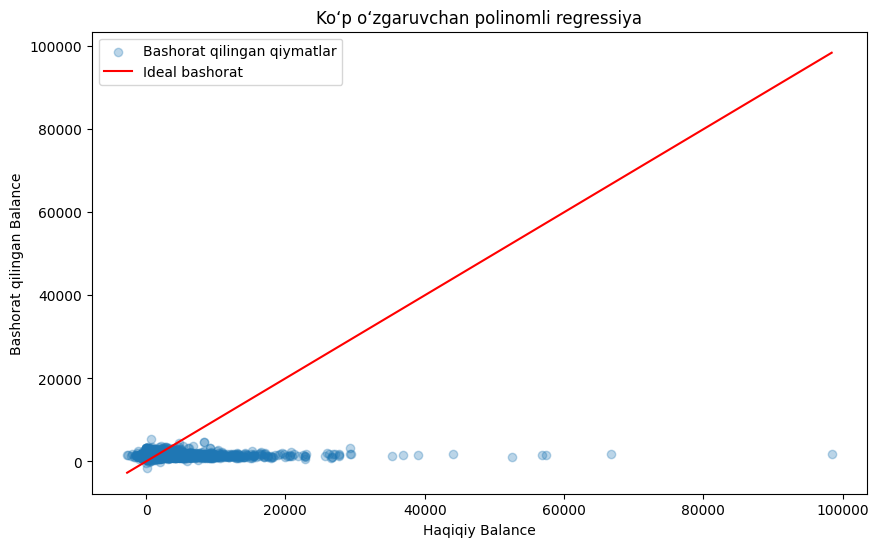

In [18]:
# 4.3. Grafik orqali natijalarni ko‘rish

plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_pred_poly_multi,
    alpha=0.3,
    label="Bashorat qilingan qiymatlar"
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    label="Ideal bashorat"
)

plt.xlabel("Haqiqiy Balance")
plt.ylabel("Bashorat qilingan Balance")
plt.title("Ko‘p o‘zgaruvchan polinomli regressiya")
plt.legend()
plt.show()

In [19]:
# 4.4. Natijalarni jadvalda ko‘rish

natijalar = pd.DataFrame({
    "Haqiqiy qiymat": y_test.values[:10],
    "Bashorat qilingan qiymat": y_pred_poly_multi[:10]
})

print(natijalar)

   Haqiqiy qiymat  Bashorat qilingan qiymat
0             580               1359.381975
1            3644               1449.080496
2             538               1172.698857
3            1773               1254.183279
4             217               1725.979873
5            1134               1028.995172
6            1085                904.793648
7             127               1152.515071
8               3               1123.289071
9             258               1380.457402


In [20]:
# 5. Pipeline - bir nechta amallarni yagona ketma-ketlikda bajarishga imkon beradi.

# Biz quyidagi amallarni birlashtiramiz:
# 1. StandardScaler — ma’lumotlarni standartlashtirish.
# 2. PolynomialFeatures — polinomial xususiyatlarni yaratish.
# 3. LinearRegression — regressiya modelini yaratish.

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(
        degree=2,
        include_bias=False
    )),
    ('model', LinearRegression())
])

# Modelni o'qitish
pipeline.fit(X_train, y_train)

# Bashorat
y_pred_pipeline = pipeline.predict(X_test)

print("Pipeline muvaffaqiyatli bajarildi.")

Pipeline muvaffaqiyatli bajarildi.


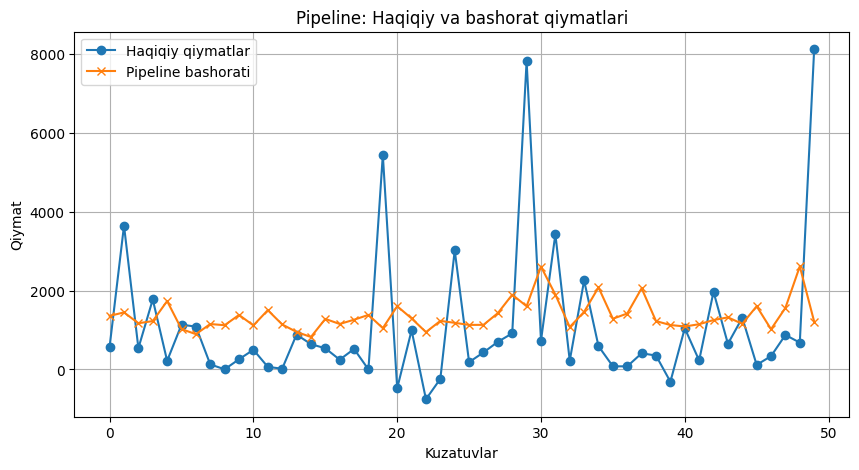

In [21]:

plt.figure(figsize=(10, 5))

plt.plot(
    np.array(y_test)[:50],
    label="Haqiqiy qiymatlar",
    marker="o"
)

plt.plot(
    y_pred_pipeline[:50],
    label="Pipeline bashorati",
    marker="x"
)

plt.title("Pipeline: Haqiqiy va bashorat qiymatlari")
plt.xlabel("Kuzatuvlar")
plt.ylabel("Qiymat")
plt.legend()
plt.grid(True)
plt.show()


In [22]:
# 6. Namunaviy baholash choralari - Model sifatini baholash uchun ikkita asosiy ko‘rsatkichdan foydalanamiz.

# 6.1. O‘rtacha kvadratik xato (MSE)

# MSE qiymati qancha kichik bo‘lsa, bashoratlarning kvadratik xatoliklari shuncha kichik bo‘ladi.

mse = mean_squared_error(
    y_test,
    y_pred_pipeline
)

print("MSE:", mse)

MSE: 9695313.307575254


In [23]:
# 6.2. R-squared (R²) - model bog‘liq o‘zgaruvchidagi o‘zgarishlarning qancha qismini tushuntirishini ko‘rsatadi.

# R² qiymati 1 ga yaqinlashgani sari modelning tushuntirish qobiliyati yaxshiroq bo‘ladi. Manfiy qiymat ham kuzatilishi mumkin.

r2 = r2_score(
    y_test,
    y_pred_pipeline
)

print("R-squared:", r2)

R-squared: 0.010355547583361102


In [24]:
# 6.3. Barcha modellarni taqqoslash

models = {
    "Oddiy chiziqli regressiya": y_pred_simple,
    "Ko'p chiziqli regressiya": y_pred_multi,
    "Polinomial regressiya": y_pred_poly,
    "Ko'p o'zgaruvchili polinomial regressiya": y_pred_poly_multi,
    "Pipeline": y_pred_pipeline
}

results = []

for name, prediction in models.items():

    mse = mean_squared_error(y_test_s, prediction) if name in [
        "Oddiy chiziqli regressiya",
        "Polinomial regressiya"
    ] else mean_squared_error(y_test, prediction)

    r2 = r2_score(y_test_s, prediction) if name in [
        "Oddiy chiziqli regressiya",
        "Polinomial regressiya"
    ] else r2_score(y_test, prediction)

    results.append({
        "Model": name,
        "MSE": mse,
        "R-squared": r2
    })

results_df = pd.DataFrame(results)

print(results_df)

                                      Model           MSE  R-squared
0                 Oddiy chiziqli regressiya  9.711320e+06   0.008722
1                  Ko'p chiziqli regressiya  9.711411e+06   0.008712
2                     Polinomial regressiya  9.707494e+06   0.009112
3  Ko'p o'zgaruvchili polinomial regressiya  9.697285e+06   0.010154
4                                  Pipeline  9.695313e+06   0.010356


In [25]:
# 7. Bashorat qilish va qaror qabul qilish - Yangi mijozlar ma’lumotlari asosida hisobdagi mablag‘ni bashorat qilamiz.

# Yangi mijozlar ma'lumotlari
new_customers = pd.DataFrame({
    'age': [30, 45, 60],
    'day': [10, 15, 20],
    'duration': [200, 300, 150],
    'campaign': [1, 2, 3],
    'pdays': [-1, 100, -1],
    'previous': [0, 1, 0]
})

# Pipeline orqali bashorat
predictions = pipeline.predict(new_customers)

# Natijalarni chiqarish
new_customers['predicted_balance'] = predictions

print(new_customers)

   age  day  duration  campaign  pdays  previous  predicted_balance
0   30   10       200         1     -1         0        1117.130279
1   45   15       300         2    100         1        1604.424098
2   60   20       150         3     -1         0        1890.411144


In [ ]:
# ANOVA testi - mijozlarning age, balance, duration kabi sonli ustunlari y (obuna bo‘lgan yoki bo‘lmagan) guruhlari bo‘yicha taqqoslanadi.

import pandas as pd
import numpy as np
from scipy.stats import f_oneway

# Sonli ustunlar
numeric_columns = [
    'age', 'balance', 'day', 'duration',
    'campaign', 'pdays', 'previous'
]

anova_results = []

# Har bir sonli ustun uchun ANOVA
for column in numeric_columns:

    group_yes = df[df['y'] == 'yes'][column].dropna()
    group_no = df[df['y'] == 'no'][column].dropna()

    f_stat, p_value = f_oneway(group_yes, group_no)

    anova_results.append({
        'Ustun': column,
        'F-statistic': f_stat,
        'P-value': p_value,
        'Natija': 'Ahamiyatli' if p_value < 0.05 else 'Ahamiyatli emas'
    })

# Natijalarni jadvalda chiqarish
anova_df = pd.DataFrame(anova_results)

print("ANOVA TEST NATIJALARI:")
print(anova_df.to_string(index=False))

ANOVA TEST NATIJALARI:
   Ustun  F-statistic       P-value     Natija
     age    28.625233  8.825644e-08 Ahamiyatli
 balance   126.572276  2.521114e-29 Ahamiyatli
     day    36.359010  1.653880e-09 Ahamiyatli
duration  8333.761148  0.000000e+00 Ahamiyatli
campaign   243.358404  1.012347e-54 Ahamiyatli
   pdays   490.696563 3.790553e-108 Ahamiyatli
previous   396.443989  7.801830e-88 Ahamiyatli


In [29]:
# P-value natijalarini chiqarish - bu alohida test emas, balki statistik testlar natijasida olinadigan qiymat. 
# Yuqoridagi ANOVA natijalaridan P-value qiymatlarini alohida chiqaramiz.

print("P-VALUE TAHLILI")
print("-" * 45)

for index, row in anova_df.iterrows():

    print(f"\nUstun: {row['Ustun']}")
    print(f"F-statistic: {row['F-statistic']:.4f}")
    print(f"P-value: {row['P-value']:.12e}")

    if row['P-value'] < 0.05:
        print("Xulosa: Statistik jihatdan ahamiyatli.")
    else:
        print("Xulosa: Statistik jihatdan ahamiyatli emas.")

P-VALUE TAHLILI
---------------------------------------------

Ustun: age
F-statistic: 28.6252
P-value: 8.825643691922e-08
Xulosa: Statistik jihatdan ahamiyatli.

Ustun: balance
F-statistic: 126.5723
P-value: 2.521113691875e-29
Xulosa: Statistik jihatdan ahamiyatli.

Ustun: day
F-statistic: 36.3590
P-value: 1.653880160818e-09
Xulosa: Statistik jihatdan ahamiyatli.

Ustun: duration
F-statistic: 8333.7611
P-value: 0.000000000000e+00
Xulosa: Statistik jihatdan ahamiyatli.

Ustun: campaign
F-statistic: 243.3584
P-value: 1.012347364209e-54
Xulosa: Statistik jihatdan ahamiyatli.

Ustun: pdays
F-statistic: 490.6966
P-value: 3.790553319478e-108
Xulosa: Statistik jihatdan ahamiyatli.

Ustun: previous
F-statistic: 396.4440
P-value: 7.801830349808e-88
Xulosa: Statistik jihatdan ahamiyatli.


In [ ]:
# Chi-Square (χ²) testi - kategorik ustunlar bilan y ustuni o‘rtasidagi bog‘liqlikni tekshiradi.

from scipy.stats import chi2_contingency

# Kategorik ustunlar
categorical_columns = [
    'job', 'marital', 'education', 'default',
    'housing', 'loan', 'contact', 'month', 'poutcome'
]

chi_results = []

# Har bir kategorik ustun uchun Chi-Square testi
for column in categorical_columns:

    contingency_table = pd.crosstab(df[column], df['y'])

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    chi_results.append({
        'Ustun': column,
        'Chi2-statistic': chi2,
        'P-value': p_value,
        'Degrees of Freedom': dof,
        'Natija': 'Bog‘liqlik mavjud' if p_value < 0.05
                  else 'Bog‘liqlik aniqlanmadi'
    })

chi_df = pd.DataFrame(chi_results)

print("CHI-SQUARE TEST NATIJALARI:")
print(chi_df.to_string(index=False))

CHI-SQUARE TEST NATIJALARI:
    Ustun  Chi2-statistic       P-value  Degrees of Freedom            Natija
      job      836.105488 3.337122e-172                  11 Bog‘liqlik mavjud
  marital      196.495946  2.145100e-43                   2 Bog‘liqlik mavjud
education      238.923506  1.626656e-51                   3 Bog‘liqlik mavjud
  default       22.202250  2.453861e-06                   1 Bog‘liqlik mavjud
  housing      874.822449 2.918798e-192                   1 Bog‘liqlik mavjud
     loan      209.616980  1.665061e-47                   1 Bog‘liqlik mavjud
  contact     1035.714225 1.251738e-225                   2 Bog‘liqlik mavjud
    month     3061.838938  0.000000e+00                  11 Bog‘liqlik mavjud
 poutcome     4391.506589  0.000000e+00                   3 Bog‘liqlik mavjud
